# DeepDive | AI Bootcamp 03
## Klasteryzacja: K-means, K-means++ i HCA

**Dane:** Palmer Penguins · **Cel:** porównać grupowanie z rzeczywistymi gatunkami.  
**Przebieg:** dane → K-means → K-means++ → HCA → wnioski.

Kolor punktu oznacza **gatunek**, kształt — **przypisany klaster**. Gatunki nie są wykorzystywane do trenowania modeli.

### 1 · Dane

**01.** Wczytaj dane. Sprawdź liczebność gatunków i braki w czterech pomiarach.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

penguins = pd.read_csv('penguins.csv')
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
print(penguins['species'].value_counts())
print(penguins[features].isna().sum())

Adelie       152
Gentoo       124
Chinstrap     68
Name: species, dtype: int64
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64


**02.** Usuń brakujące pomiary i wystandaryzuj cztery cechy. `species` zachowaj wyłącznie do oceny wyników.

In [2]:
data = penguins.dropna(subset=features).copy()
X = StandardScaler().fit_transform(data[features])
print(X.shape)

(342, 4)


**03.** Zobacz faktyczne gatunki na wykresie dwóch pomiarów. Pamiętaj: modele wykorzystają **4 cechy**, nie tylko te na osiach.

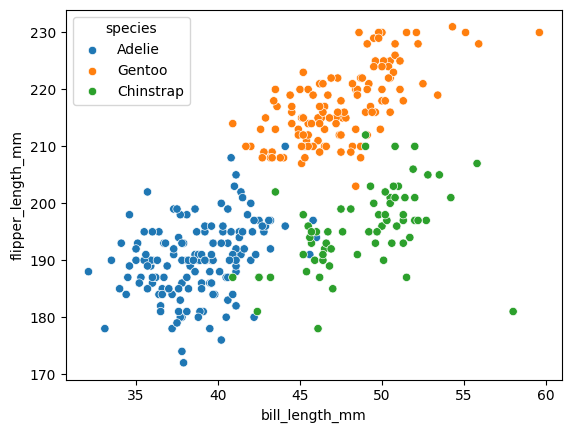

In [3]:
sns.scatterplot(data=data, x='bill_length_mm', y='flipper_length_mm', hue='species')
plt.show()

### 2 · K-means

**04.** Uruchom K-means z losową inicjalizacją dla `k=3`. Sprawdź wynik na wykresie: kolor = gatunek, kształt = klaster.

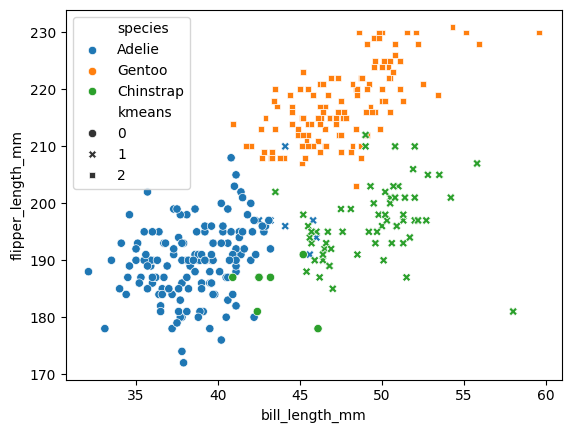

In [4]:
km = KMeans(n_clusters=3, init='random', n_init=1, random_state=42)
data['kmeans'] = km.fit_predict(X).astype(str)
sns.scatterplot(data=data, x='bill_length_mm', y='flipper_length_mm', hue='species', style='kmeans')
plt.show()

**05.** Dobierz liczbę klastrów: metoda łokcia i silhouette score (`k=2…7`).

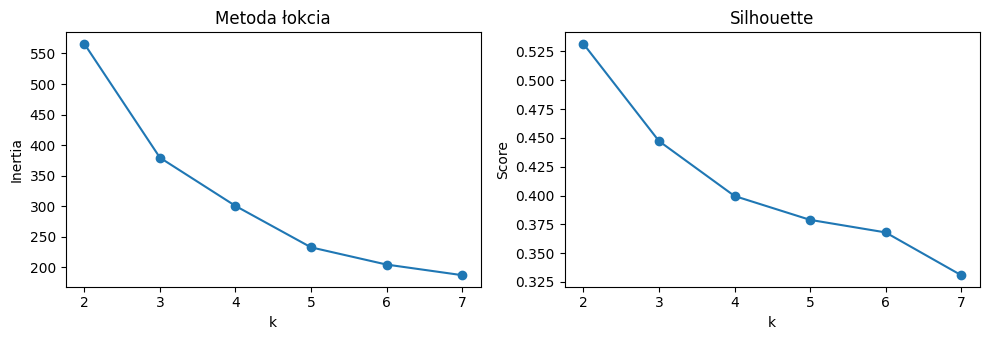

In [5]:
ks = range(2, 8)
inertia = []
silhouette = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(list(ks), inertia, marker='o')
axes[0].set(title='Metoda łokcia', xlabel='k', ylabel='Inertia')
axes[1].plot(list(ks), silhouette, marker='o')
axes[1].set(title='Silhouette', xlabel='k', ylabel='Score')
plt.tight_layout()
plt.show()

### 3 · K-means++

**06.** Zmień wyłącznie inicjalizację na `k-means++`. Porównaj `inertia` i gatunki w klastrach. `n_init=1` pozwala porównać pojedyncze uruchomienia.

In [6]:
km_plus = KMeans(n_clusters=3, init='k-means++', n_init=1, random_state=42)
data['kmeans++'] = km_plus.fit_predict(X).astype(str)
print('K-means:', round(km.inertia_, 2))
print('K-means++:', round(km_plus.inertia_, 2))
print(pd.crosstab(data['species'], data['kmeans++']))

K-means: 381.29
K-means++: 379.39
kmeans++    0    1    2
species                
Adelie     24    0  127
Chinstrap  63    0    5
Gentoo      0  123    0


**07.** Porównaj na wykresach oba podziały. Gatunek jest oznaczony kolorem, klaster — kształtem.

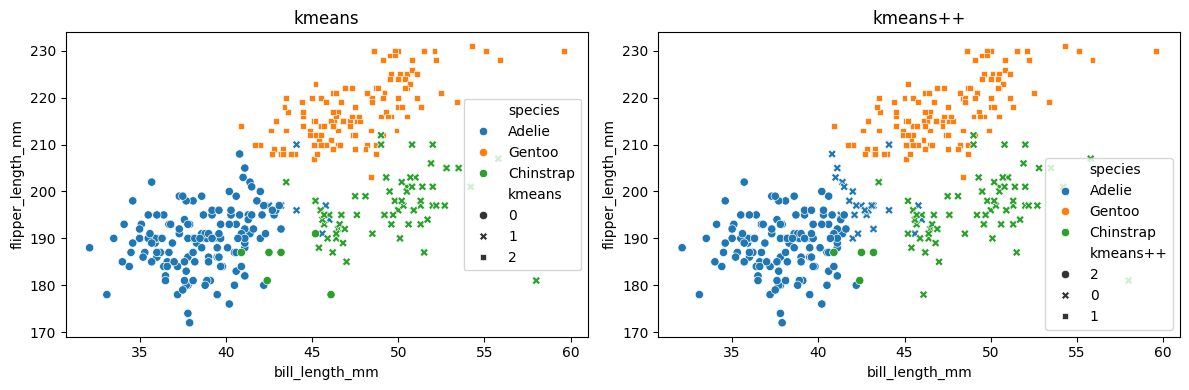

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ['kmeans', 'kmeans++']):
    sns.scatterplot(data=data, x='bill_length_mm', y='flipper_length_mm',
                    hue='species', style=column, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

### 4 · HCA: cztery sposoby łączenia

Porównamy `single` (najbliższe punkty), `complete` (najdalsze), `average` (średnia odległość) i `ward` (wzrost wariancji). Wszystkie metody dostają te same standaryzowane dane.

**08.** Narysuj cztery dendrogramy. Dla czytelności użyjemy próby 45 obserwacji (po 15 z każdego gatunku); gatunek nie jest wykorzystywany w samym HCA.

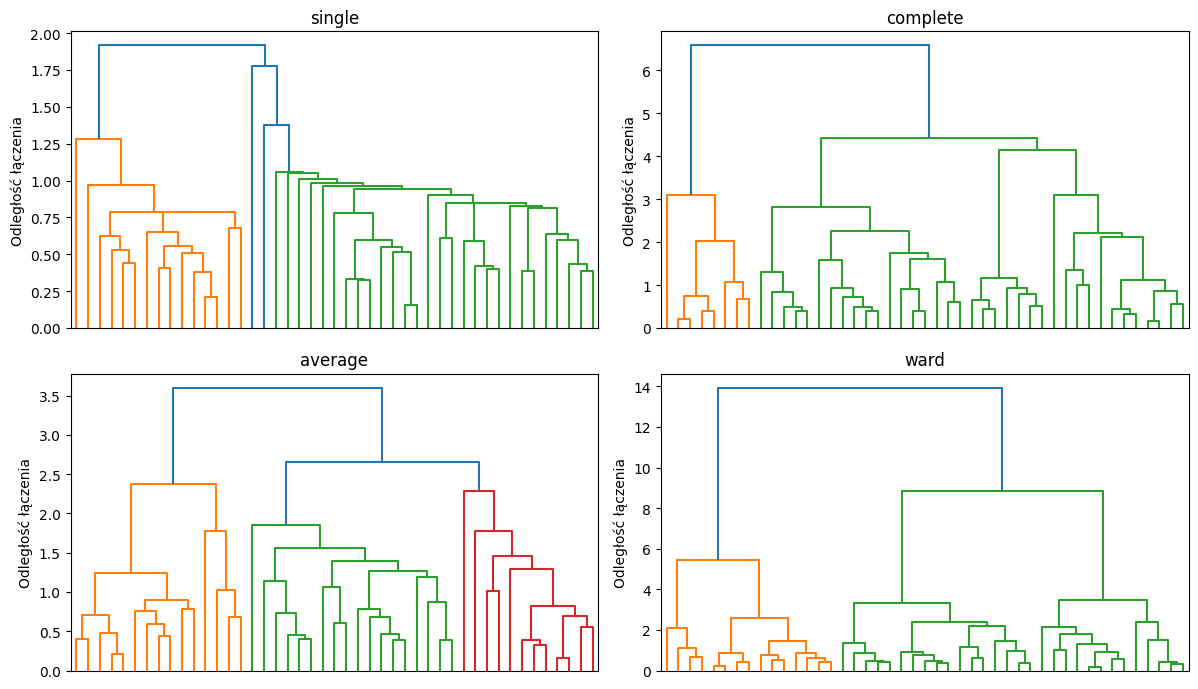

In [8]:
sample = data.groupby('species').sample(n=15, random_state=42)
X_sample = StandardScaler().fit(data[features]).transform(sample[features])
methods = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, method in zip(axes.flat, methods):
    dendrogram(linkage(X_sample, method=method), ax=ax, no_labels=True)
    ax.set(title=method, ylabel='Odległość łączenia')
plt.tight_layout()
plt.show()

**09.** Uruchom cztery warianty HCA na wszystkich obserwacjach, zawsze z 3 klastrami. Pokaż wyniki na tych samych osiach. Kolor = klaster, kształt = rzeczywisty gatunek.

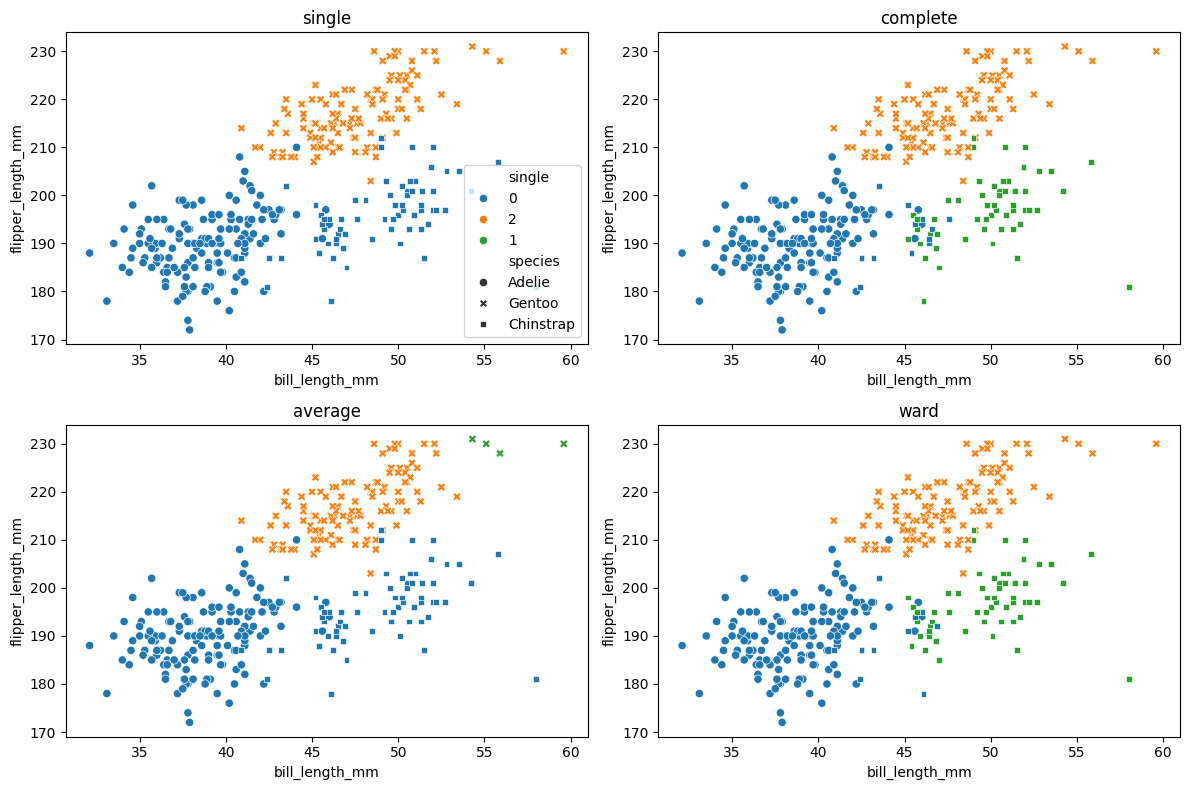

In [9]:
hca_results = {}
for method in methods:
    labels = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X)
    data[method] = labels.astype(str)
    hca_results[method] = labels

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, method in zip(axes.flat, methods):
    sns.scatterplot(data=data, x='bill_length_mm', y='flipper_length_mm',
                    hue=method, style='species', ax=ax, legend=(method == 'single'))
    ax.set_title(method)
plt.tight_layout()
plt.show()

**10.** Porównaj silhouette score oraz tablice gatunek × klaster dla metod HCA. Etykiety klastrów (`0, 1, 2`) nie mają tej samej interpretacji między metodami.

In [10]:
scores = {'K-means': silhouette_score(X, km.labels_),
          'K-means++': silhouette_score(X, km_plus.labels_)}
for method, labels in hca_results.items():
    scores[method] = silhouette_score(X, labels)
print(pd.Series(scores).round(3).sort_values(ascending=False))

for method in methods:
    print('\n', method)
    print(pd.crosstab(data['species'], data[method]))

single       0.469
K-means      0.459
ward         0.454
complete     0.452
K-means++    0.447
average      0.442
dtype: float64

 single
single       0  1    2
species               
Adelie     151  0    0
Chinstrap   67  1    0
Gentoo       0  0  123

 complete
complete     0    1   2
species                
Adelie       0  151   0
Chinstrap    0   14  54
Gentoo     123    0   0

 average
average      0    1  2
species               
Adelie     151    0  0
Chinstrap   68    0  0
Gentoo       0  119  4

 ward
ward         0    1   2
species                
Adelie     151    0   0
Chinstrap   11    0  57
Gentoo       0  123   0


### Wnioski

1. Który gatunek jest najłatwiejszy do wydzielenia? Po czym to widać?
2. Czy K-means++ zawsze daje niższe `inertia` niż losowa inicjalizacja w pojedynczym uruchomieniu?
3. Jakie różnice między `single`, `complete`, `average` i `ward` widać na dendrogramach i wykresach?
4. Czy najwyższy silhouette score musi oznaczać największą zgodność z gatunkami?